# Analise dos Micro Dados ENEM 2025

Este projeto visa a análise dos microdados da edição ENEM 2025 fornecidos pelo INEP no endereço https://www.gov.br/inep/pt-br/acesso-a-informacao/dados-abertos/microdados/enem

In [1]:
import pandas as pd
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import seaborn as sns
import textwrap
from matplotlib.ticker import FuncFormatter

## Análise exploratória de alguns dados

Nessa seção serão feitas análises superficias, obtenção de estatísticas simples e classificação de certas categorias de dados com objetivo de responder perguntas como: Qual o estado com mais participantes? qual faixa etária mais participante? porcentagens de estado civíl dos candidatos, etc.

In [2]:
#Leitura dos dados dos participantes
participantes_df = pd.read_csv('DADOS/PARTICIPANTES_2025.csv', encoding='latin1', sep=';')
participantes_df.head()

,NU_INSCRICAO,NU_ANO,TP_FAIXA_ETARIA,TP_SEXO,TP_ESTADO_CIVIL,TP_COR_RACA,TP_NACIONALIDADE,TP_ST_CONCLUSAO,TP_ANO_CONCLUIU,TP_ENSINO,...,Q014,Q015,Q016,Q017,Q018,Q019,Q020,Q021,Q022,Q023
0,210066506229,2025,6,F,1,2,2,1,4,NaN,...,A,A,A,A,A,A,A,A,B,A
1,210066506230,2025,3,M,1,1,1,2,0,1.0,...,A,B,B,A,C,A,B,B,B,A
2,210066506231,2025,2,F,1,1,1,3,0,NaN,...,A,A,B,A,A,A,B,C,C,C
3,210066506232,2025,2,M,1,3,2,2,0,1.0,...,A,B,A,A,B,A,B,B,D,D
4,210066506233,2025,1,F,1,1,1,3,0,NaN,...,B,B,B,B,D,B,B,D,E,D


In [3]:
#Leitura dos dados de prova
resultados_df = pd.read_csv('DADOS/RESULTADOS_2025.csv', encoding='ISO-8859-1', sep=';')
resultados_df

,NU_SEQUENCIAL,NU_ANO,CO_ESCOLA,CO_MUNICIPIO_ESC,NO_MUNICIPIO_ESC,CO_UF_ESC,SG_UF_ESC,TP_DEPENDENCIA_ADM_ESC,TP_LOCALIZACAO_ESC,TP_SIT_FUNC_ESC,...,NU_NOTA_COMP3_AV3,NU_NOTA_COMP4_AV3,NU_NOTA_COMP5_AV3,TP_STATUS_REDACAO_AV4,NU_NOTA_AV4,NU_NOTA_COMP1_AV4,NU_NOTA_COMP2_AV4,NU_NOTA_COMP3_AV4,NU_NOTA_COMP4_AV4,NU_NOTA_COMP5_AV4
0,206403,2025,33083592.0,3304557.0,Rio de Janeiro,33.0,RJ,2.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3604651,2025,21017115.0,2111300.0,São Luís,21.0,MA,2.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1461268,2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4301058,2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,3148322,2025,35006207.0,3552205.0,Sorocaba,35.0,SP,4.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4810767,1966623,2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,120.0,120.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4810768,1661560,2025,29272696.0,2912301.0,Ibicuí,29.0,BA,2.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4810769,2464303,2025,41133757.0,4106902.0,Curitiba,41.0,PR,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4810770,3164695,2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
#Seleção de coluna específica
coluna_idade = participantes_df['TP_FAIXA_ETARIA']

In [5]:
coluna_idade.value_counts().sort_index()

TP_FAIXA_ETARIA
1      578654
2     1021540
3     1151467
4      483303
5      271801
6      178368
7      133343
8      104839
9       87249
10      74998
11     253931
12     150564
13     113921
14      84093
15      54700
16      34007
17      19343
18       9143
19       3834
20       1674
Name: count, dtype: int64

<Axes: >

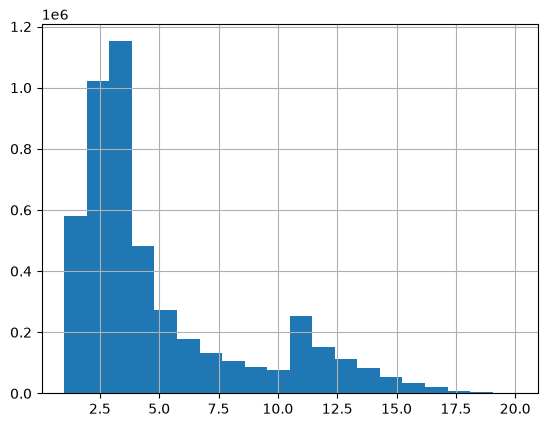

In [6]:
#Histograma com faixas etárias
#Um histograma rápido para facilitar a leitura
coluna_idade.hist(bins=20)

Aqui vale ressaltar que a partir da categoria 11 o intervalo de idades varia nas respostas da faixa etária. É o local em que a curva sobe novamente, estando agrupados em idades de variação de 4 anos a partir desse ponto.

In [59]:
#Seleção de Estados
Estados = participantes_df['SG_UF_PROVA']
Estados.value_counts()

SG_UF_PROVA
SP    751612
MG    464937
BA    427983
RJ    328943
PA    289328
CE    275902
PE    272279
MA    211370
PR    195836
RS    186503
GO    166747
PB    142035
PI    120032
RN    113208
AM    110831
SC    110459
AL     96480
ES     85910
DF     82955
MT     80396
SE     78341
MS     57932
RO     46798
TO     37650
AP     33190
AC     28957
RR     14158
Name: count, dtype: int64

In [61]:
# Vamos montar um histograma para facilitar a visualização
# Somando as respostas dos candidatos para cada Estado
estados_df = participantes_df['SG_UF_PROVA'].value_counts().reset_index(name='Quantidade')
estados_df

,SG_UF_PROVA,Quantidade
0,SP,751612
1,MG,464937
2,BA,427983
3,RJ,328943
4,PA,289328
5,CE,275902
6,PE,272279
7,MA,211370
8,PR,195836
9,RS,186503


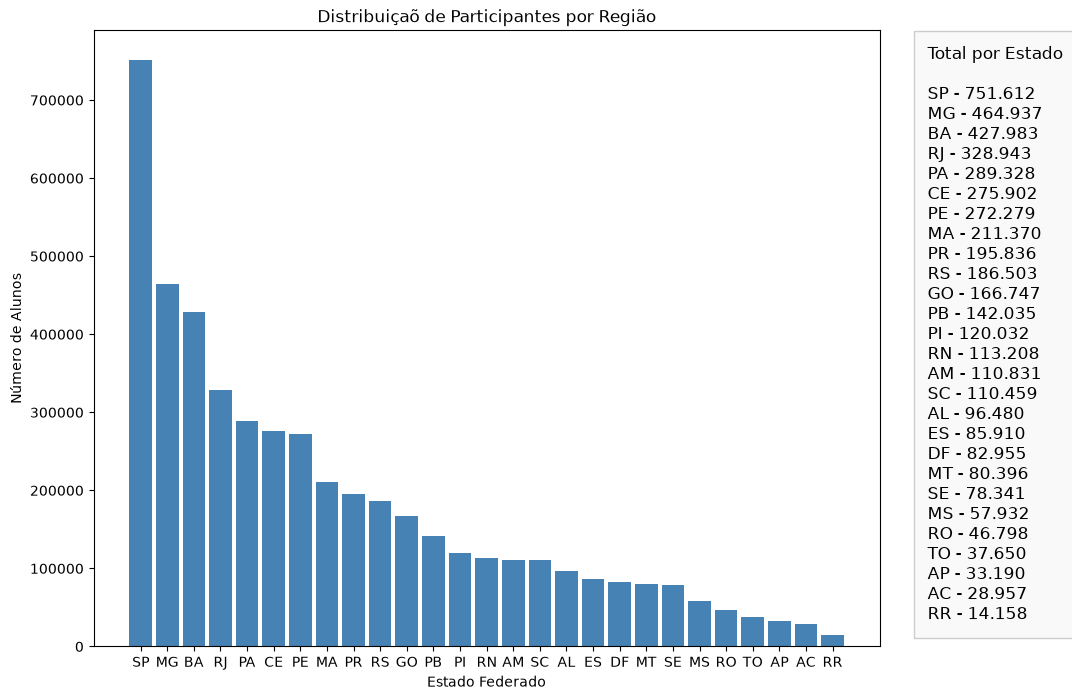

In [83]:
fig, ax = plt.subplots(figsize=(12,8))
# Definindo colunas para o grafico de barras
histograma = ax.bar(estados_df['SG_UF_PROVA'], estados_df['Quantidade'],
                    color="steelblue",
                   width=0.85)

# 3. Títulos e rótulos
plt.title("Distribuiçaõ de Participantes por Região")
ax.set_xlabel("Estado Federado")
ax.set_ylabel("Número de Alunos")

texto_legenda = "Total por Estado\n\n" + "\n".join(
    [f"{row.SG_UF_PROVA} - {int(row.Quantidade):,}".replace(',', '.') for row in estados_df.itertuples()]
)

fig.text(
    0.82,
    0.5,
    texto_legenda,
    fontsize=12,  # Fonte menor para caber bem devido ao tamanho dos textos de renda
    verticalalignment="center",
    bbox=dict(
        boxstyle="square,pad=0.8",
        facecolor="#f9f9f9",
        edgecolor="#cccccc",
        linewidth=1,
    ),
)

plt.subplots_adjust(right=0.78)

plt.show()

In [9]:
#Seleção do estado civil
estado_civil = participantes_df['TP_ESTADO_CIVIL']

In [10]:
#Contagem de estado civil por categoria
estado_civil.value_counts()

TP_ESTADO_CIVIL
1    4227523
2     327242
0     165283
3      84054
4       6670
Name: count, dtype: int64

In [11]:
#Porcentagem de participantes em cada estado civil. 0- Naõ informado,
#1 - Solteiro(a), 2 - União Estável/Casado(a)/Mora com campanheiro(a), 3 - Divorciado(a)/Desquitado(a)/Separado(a), 4 - Viúva(o)
dist_estado_civi = (estado_civil.value_counts(normalize=True) * 100)
dist_estado_civi

TP_ESTADO_CIVIL
1    87.876187
2     6.802276
0     3.435686
3     1.747204
4     0.138647
Name: proportion, dtype: float64

In [12]:
#Porcentagem de participantes em cada estado civil. 0- Naõ informado,
#1 - Solteiro(a), 2 - União Estável/Casado(a)/Mora com campanheiro(a), 3 - Viúva(o), 4 - 
dist_estado_civi = (estado_civil.value_counts(normalize=True) * 100)
dist_estado_civi

TP_ESTADO_CIVIL
1    87.876187
2     6.802276
0     3.435686
3     1.747204
4     0.138647
Name: proportion, dtype: float64

O parâmetro normalize define o valor de cada tipo de dados contado entre 0 e 1, fazendo uma porporção com o valor total. Na prática: uma porcentagem do valor total. Sendo assim, 87,88 % dos candidatos são solteiros.

In [13]:
#Seleção da coluna Sexo
tp_sexo = participantes_df['TP_SEXO']
tp_sexo

0          F
1          M
2          F
3          M
4          F
          ..
4810767    F
4810768    M
4810769    M
4810770    F
4810771    F
Name: TP_SEXO, Length: 4810772, dtype: str

In [14]:
dist_tp_sexo = tp_sexo.value_counts()
dist_tp_sexo

TP_SEXO
F    2889026
M    1921746
Name: count, dtype: int64

In [15]:
percentTpSexo = tp_sexo.value_counts(normalize=True)*100
percentTpSexo

TP_SEXO
F    60.053272
M    39.946728
Name: proportion, dtype: float64

## Comparando algumas notas:

In [16]:
select_cols = ['SG_UF_PROVA', 'NU_NOTA_REDACAO']
RedacaoEstado = resultados_df.filter(items=select_cols).dropna()
RedacaoEstado.head()

,SG_UF_PROVA,NU_NOTA_REDACAO
0,RJ,640.0
2,MA,0.0
4,SP,860.0
5,PI,680.0
6,MG,540.0


In [17]:
# Uma descrição geral dos dados por Estado
RedacaoEstado.groupby('SG_UF_PROVA').describe()

NU_NOTA_REDACAO                                                    \
                      count        mean         std  min    25%    50%    75%   
SG_UF_PROVA                                                                     
AC                  18991.0  554.583750  201.825174  0.0  460.0  560.0  680.0   
AL                  70880.0  539.418736  243.990075  0.0  440.0  580.0  700.0   
AM                  65626.0  500.475726  222.534332  0.0  420.0  540.0  620.0   
AP                  22944.0  543.537308  217.701988  0.0  460.0  560.0  680.0   
BA                 302415.0  557.297951  214.500567  0.0  460.0  580.0  680.0   
CE                 216181.0  567.598725  242.640145  0.0  460.0  600.0  740.0   
DF                  60673.0  609.835347  195.948247  0.0  520.0  620.0  740.0   
ES                  60911.0  598.552971  216.928275  0.0  500.0  620.0  740.0   
GO                 118643.0  610.710619  200.096089  0.0  520.0  620.0  740.0   
MA                 152518.0  538.365832  229.997049  0.0  440.0  560.0  680.0   
MG                 326835.0  620.225618  197.268494  0.0  520.0  620.0  760.0   
MS                  40989.0  559.951206  204.932819  0.0  460.0  580.0  680.0   
MT                  51597.0  559.763165  219.438842  0.0  460.0  580.0  700.0   
PA                 202633.0  535.616903  223.507114  0.0  440.0  560.0  680.0   
PB                 105666.0  579.548956  232.677447  0.0  480.0  600.0  740.0   
PE                 202852.0  564.872715  228.223609  0.0  460.0  600.0  720.0   
PI                  89161.0  571.616290  226.757390  0.0  460.0  580.0  720.0   
PR                 142507.0  580.030314  186.268437  0.0  480.0  580.0  700.0   
RJ                 235563.0  603.899848  199.116388  0.0  500.0  600.0  740.0   
RN                  85759.0  588.171970  210.347511  0.0  480.0  600.0  720.0   
RO                  31620.0  542.339658  218.855572  0.0  460.0  560.0  680.0   
RR                   9030.0  520.808416  224.844342  0.0  440.0  560.0  660.0   
RS                 132433.0  599.719405  204.172777  0.0  500.0  600.0  740.0   
SC                  79740.0  601.168297  197.661924  0.0  520.0  620.0  720.0   
SE                  59927.0  580.959501  231.887427  0.0  480.0  600.0  740.0   
SP                 544811.0  607.282048  184.680011  0.0  520.0  620.0  720.0   
TO                  26650.0  551.932458  221.912168  0.0  460.0  580.0  680.0   

                     
                max  
SG_UF_PROVA          
AC            980.0  
AL           1000.0  
AM            980.0  
AP            980.0  
BA           1000.0  
CE           1000.0  
DF            980.0  
ES            980.0  
GO            980.0  
MA            980.0  
MG            980.0  
MS            980.0  
MT            980.0  
PA            980.0  
PB            980.0  
PE           1000.0  
PI            980.0  
PR            980.0  
RJ           1000.0  
RN            980.0  
RO            980.0  
RR            960.0  
RS           1000.0  
SC            980.0  
SE            980.0  
SP            980.0  
TO            980.0

## Indicadores Socioeconômicos

Nessa secção vamos exploras alguns indicadores socioeconômicos como escolaridade parental, faixa de renda familiar e as relações entre essas categorias. Vamos também explorar a faixa de renda de acordo com as respostas sobre identidade racial

In [18]:
# Começaremos pela Escolaridade dos Pais

In [19]:
participantes_df.columns.values

<StringArray>
[      'NU_INSCRICAO',             'NU_ANO',    'TP_FAIXA_ETARIA',
            'TP_SEXO',    'TP_ESTADO_CIVIL',        'TP_COR_RACA',
   'TP_NACIONALIDADE',    'TP_ST_CONCLUSAO',    'TP_ANO_CONCLUIU',
          'TP_ENSINO',       'IN_TREINEIRO', 'CO_MUNICIPIO_PROVA',
 'NO_MUNICIPIO_PROVA',        'CO_UF_PROVA',        'SG_UF_PROVA',
               'Q001',               'Q002',               'Q003',
               'Q004',               'Q005',               'Q006',
               'Q007',               'Q008',               'Q009',
               'Q010',               'Q011',               'Q012',
               'Q013',               'Q014',               'Q015',
               'Q016',               'Q017',               'Q018',
               'Q019',               'Q020',               'Q021',
               'Q022',               'Q023']
Length: 38, dtype: str

In [20]:
select_col_pais = ['NU_INSCRICAO', 'TP_COR_RACA', 'SG_UF_PROVA', 'Q001', 'Q002', 'Q007']

In [21]:
EscolaridadePais = participantes_df.filter(items=select_col_pais)
EscolaridadePais.sort_values(by='SG_UF_PROVA').head()

,NU_INSCRICAO,TP_COR_RACA,SG_UF_PROVA,Q001,Q002,Q007
1884686,210068441475,3,AC,E,E,B
2347800,210068915212,1,AC,D,E,B
2201485,210068763851,3,AC,G,E,B
3325535,210069918852,1,AC,H,G,G
3853289,210070459232,1,AC,G,G,C


## Vamos analisar então os dados socioeconomicos!

### Primeiro vamos definir um dicionario!

In [22]:
q001eq002dic = {'A' : 'Nunca estudou.',
                'B' : 'Não completou a 4ª série/5º ano do Ensino Fundamental',
                'C' : 'Completou a 4ª série/5º ano, mas não completou a 8ª série/9º ano do Ensino Fundamental.',
                'D' : 'Completou a 8ª série/9º ano do Ensino Fundamental, mas não completou o Ensino Médio.',
                'E' : 'Completou o Ensino Médio, mas não completou a Faculdade.',
                'F' : 'Completou a Faculdade, mas não completou a Pós-graduação.',
                'G' : 'Completou a Pós-graduação.',
                'H' : 'Não sei.'}

In [23]:
q007dic = {
    "A": "Nenhuma renda",
    "B": "Até R\\$ 1.518,00",
    "C": "De R\\$ 1.518,01 até R\\$ 2.277,00",
    "D": "De R\\$ 2.277,01 até R\\$ 3.036,00",
    "E": "De R\\$ 3.036,01 até R\\$ 3.795,00",
    "F": "De R\\$ 3.795,01 até R\\$ 4.554,00",
    "G": "De R\\$ 4.554,01 até R\\$ 6.072,00",
    "H": "De R\\$ 6.072,01 até R\\$ 7.590,00",
    "I": "De R\\$ 7.590,01 até R\\$ 9.108,00",
    "J": "De R\\$ 9.108,01 até R\\$ 10.626,00",
    "K": "De R\\$ 10.626,01 até R\\$ 12.144,00",
    "L": "De R\\$ 12.144,01 até R\\$ 13.662,00",
    "M": "De R\\$ 13.662,01 até R\\$ 15.180,00",
    "N": "De R\\$ 15.180,01 até R\\$ 18.216,00",
    "O": "De R\\$ 18.216,01 até R\\$ 22.770,00",
    "P": "De R\\$ 22.770,01 até R\\$ 30.360,00",
    "Q": "Acima de R\\$ 30.360,00"
}

In [24]:
raca_dic = {0 : 'Não decalrado',
            1 :	'Branca',
            2 :	'Preta',
            3 :	'Parda',
            4 :	'Amarela',
            5 :	'Indígena'}

In [25]:
EscolaridadePais.filter(items = ['Q001', 'SG_UF_PROVA']).groupby('Q001').count()

,SG_UF_PROVA
Q001,
A,206281
B,734962
C,541875
D,636382
E,1375215
F,403810
G,333178
H,579069


In [26]:
#Adiciona uma coluna com as respostas "traduzidas"
EscolaridadePais['NO_Q001'] = [q001eq002dic[resp] for resp in EscolaridadePais.Q001]

In [27]:
EscolaridadePais.filter(items = ['NO_Q001', 'SG_UF_PROVA']).groupby('NO_Q001').count().sort_values(by='SG_UF_PROVA', ascending=False)

,SG_UF_PROVA
NO_Q001,
"Completou o Ensino Médio, mas não completou a Faculdade.",1375215
Não completou a 4ª série/5º ano do Ensino Fundamental,734962
"Completou a 8ª série/9º ano do Ensino Fundamental, mas não completou o Ensino Médio.",636382
Não sei.,579069
"Completou a 4ª série/5º ano, mas não completou a 8ª série/9º ano do Ensino Fundamental.",541875
"Completou a Faculdade, mas não completou a Pós-graduação.",403810
Completou a Pós-graduação.,333178
Nunca estudou.,206281


In [28]:
EscolaridadePais['NO_Q002'] = [q001eq002dic[resp] for resp in EscolaridadePais.Q002]

In [29]:
EscolaridadePais['RACA'] = [raca_dic[resp] for resp in EscolaridadePais.TP_COR_RACA]

In [30]:
EscolaridadePais.head()

,NU_INSCRICAO,TP_COR_RACA,SG_UF_PROVA,Q001,Q002,Q007,NO_Q001,NO_Q002,RACA
0,210066506229,2,BA,C,F,B,"Completou a 4ª série/5º ano, mas não completou...","Completou a Faculdade, mas não completou a Pós...",Preta
1,210066506230,1,BA,B,E,D,Não completou a 4ª série/5º ano do Ensino Fund...,"Completou o Ensino Médio, mas não completou a ...",Branca
2,210066506231,1,SP,E,E,F,"Completou o Ensino Médio, mas não completou a ...","Completou o Ensino Médio, mas não completou a ...",Branca
3,210066506232,3,PI,D,F,B,Completou a 8ª série/9º ano do Ensino Fundamen...,"Completou a Faculdade, mas não completou a Pós...",Parda
4,210066506233,1,MT,G,G,Q,Completou a Pós-graduação.,Completou a Pós-graduação.,Branca


### Comparação entre escolaridade dos Pais vs Mães com a Renda Familiar

In [31]:
#Adicinando resposta da questão 7, referente a faixa de renda familiar
EscolaridadePais['NO_Q007'] = [q007dic[resp] for resp in EscolaridadePais.Q007]

In [32]:
EscolaridadePais.head()

,NU_INSCRICAO,TP_COR_RACA,SG_UF_PROVA,Q001,Q002,Q007,NO_Q001,NO_Q002,RACA,NO_Q007
0,210066506229,2,BA,C,F,B,"Completou a 4ª série/5º ano, mas não completou...","Completou a Faculdade, mas não completou a Pós...",Preta,"Até R\$ 1.518,00"
1,210066506230,1,BA,B,E,D,Não completou a 4ª série/5º ano do Ensino Fund...,"Completou o Ensino Médio, mas não completou a ...",Branca,"De R\$ 2.277,01 até R\$ 3.036,00"
2,210066506231,1,SP,E,E,F,"Completou o Ensino Médio, mas não completou a ...","Completou o Ensino Médio, mas não completou a ...",Branca,"De R\$ 3.795,01 até R\$ 4.554,00"
3,210066506232,3,PI,D,F,B,Completou a 8ª série/9º ano do Ensino Fundamen...,"Completou a Faculdade, mas não completou a Pós...",Parda,"Até R\$ 1.518,00"
4,210066506233,1,MT,G,G,Q,Completou a Pós-graduação.,Completou a Pós-graduação.,Branca,"Acima de R\$ 30.360,00"


In [33]:
# 1. Criando a tabela cruzada com todos os dados para os pai e para as mães
tabela_cruzada_renda_escol_pai = pd.crosstab(
    EscolaridadePais['Q001'], 
    EscolaridadePais['Q007'], 
)

tabela_cruzada_renda_escol_mae = pd.crosstab(
    EscolaridadePais['Q002'], 
    EscolaridadePais['Q007'], 
)

# 2. Adicionando os totais de cada linha e de cada coluna usando .margins=True
tabela_com_totais_pai = pd.crosstab(
    EscolaridadePais['Q001'], 
    EscolaridadePais['Q007'], 
    margins=True,          # Adiciona a linha e a coluna 'All' (Totais),
    margins_name='Total',  # Renomeia o rótulo de 'All' para 'Total'
)

tabela_com_totais_mae = pd.crosstab(
    EscolaridadePais['Q002'], 
    EscolaridadePais['Q007'], 
    margins=True,          # Adiciona a linha e a coluna 'All' (Totais)
    margins_name='Total',  # Renomeia o rótulo de 'All' para 'Total'
)


In [34]:
# Somando as respostas dos candidatos para cada nível de escolaridade paternal
df_resposta_pais = tabela_com_totais_pai[['Total']].iloc[:-1].reset_index()
df_resposta_pais

Q007,Q001,Total
0,A,206281
1,B,734962
2,C,541875
3,D,636382
4,E,1375215
5,F,403810
6,G,333178
7,H,579069


In [35]:
# Somando as respostas dos candidatos para cada nível de escolaridade maternal
df_resposta_maes = tabela_com_totais_mae[['Total']].iloc[:-1].reset_index()
df_resposta_maes

Q007,Q002,Total
0,A,129847
1,B,513205
2,C,442474
3,D,671026
4,E,1718361
5,F,548154
6,G,570928
7,H,216777


In [36]:
# Pegando a renda a partir da tabela de resposta das mães 
#(obs: o valor total da soma de candidatos por renda familiar é igual para pai e mãe)
total_renda = tabela_com_totais_mae.transpose()[['Total']].iloc[:-1].reset_index()
total_renda

Q002,Q007,Total
0,A,479899
1,B,1644626
2,C,866020
3,D,434003
4,E,202017
5,F,233062
6,G,271843
7,H,137918
8,I,106469
9,J,85387


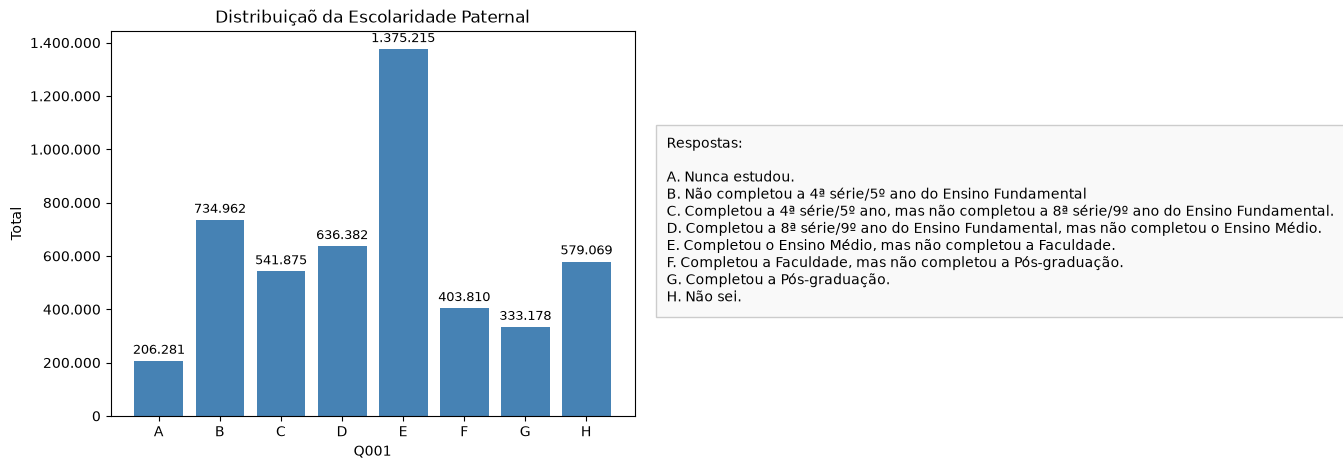

In [37]:
fig, ax = plt.subplots(figsize=(8, 5))
# Definindo colunas para o grafico de barras
histograma = ax.bar(df_resposta_pais["Q001"], df_resposta_pais["Total"], color="steelblue")
# Adicionando valores exatos acima das barras
ax.bar_label(
    histograma,
    labels=[f'{int(v):,}'.replace(',', '.') for v in df_resposta_pais["Total"]],
    padding=3,  # Espaço em pontos entre a barra e o texto
    fontsize=9  # Tamanho da fonte
)

# Desativa a notação científica
ax.ticklabel_format(style="plain", axis="y")

# Formata o eixo Y com separadores de milhar (ex: 1.500.000)
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{int(x):,}".replace(",", "."))
)

# 3. Títulos e rótulos
plt.title("Distribuiçaõ da Escolaridade Paternal")
ax.set_xlabel("Q001")
ax.set_ylabel("Total")

#Legenda

texto_legenda = "Respostas:\n\n" + "\n".join(
    [f"{k}. {v}" for k, v in q001eq002dic.items()]
)
fig.text(
    0.82,
    0.5,
    texto_legenda,
    fontsize=10, 
    verticalalignment="center",
    bbox=dict(
        boxstyle="square,pad=0.8",
        facecolor="#f9f9f9",
        edgecolor="#cccccc"),
)

plt.subplots_adjust(right=0.78)


plt.show()

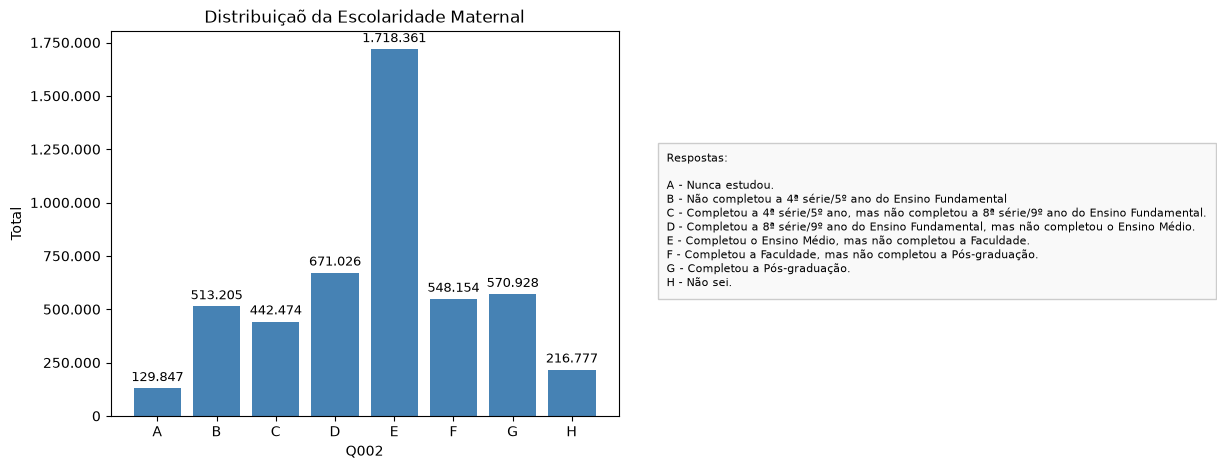

In [38]:
fig, ax = plt.subplots(figsize=(8, 5))
# Definindo colunas para o grafico de barras
histograma = ax.bar(df_resposta_maes["Q002"], df_resposta_maes["Total"], color="steelblue")
# Adicionando valores exatos acima das barras
ax.bar_label(
    histograma,
    labels=[f'{int(v):,}'.replace(',', '.') for v in df_resposta_maes["Total"]],
    padding=3,  # Espaço em pontos entre a barra e o texto
    fontsize=9  # Tamanho da fonte
)

# 1. Desativa a notação científica (tira o 10^6 do canto) e força o número plano
ax.ticklabel_format(style="plain", axis="y")

# 2. Formata o eixo Y com separadores de milhar (ex: 1.500.000)
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{int(x):,}".replace(",", "."))
)

# 3. Títulos e rótulos
# 3. Títulos e rótulos
plt.title("Distribuiçaõ da Escolaridade Maternal")
ax.set_xlabel("Q002")
ax.set_ylabel("Total")

#Legenda

texto_legenda = "Respostas:\n\n" + "\n".join(
    [f"{k} - {v}" for k, v in q001eq002dic.items()]
)
fig.text(
    0.82,
    0.5,
    texto_legenda,
    fontsize=8,  # Fonte menor para caber bem devido ao tamanho dos textos de renda
    verticalalignment="center",
    bbox=dict(
        boxstyle="square,pad=0.8",
        facecolor="#f9f9f9",
        edgecolor="#cccccc",
        linewidth=1,
    ),
)

plt.subplots_adjust(right=0.76)


plt.show()

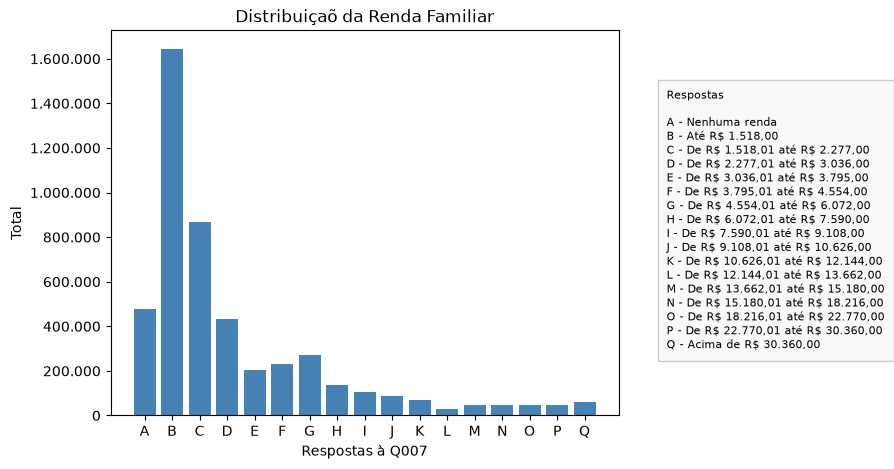

In [39]:
fig, ax = plt.subplots(figsize=(8, 5))

# Seu gráfico de barras original
ax.bar(total_renda["Q007"], total_renda["Total"], color="steelblue")

# 1. Desativa a notação científica (tira o 10^6 do canto) e força o número plano
ax.ticklabel_format(style="plain", axis="y")

# 2. Formata o eixo Y com separadores de milhar (ex: 1.500.000)
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{int(x):,}".replace(",", "."))
)

# 3. Títulos e rótulos
plt.title("Distribuiçaõ da Renda Familiar")
ax.set_xlabel("Respostas à Q007")
ax.set_ylabel("Total")

#fazendo uma legenda
texto_legenda = f"{"Respostas"}\n\n" + "\n".join(
    [f"{k} - {v}" for k, v in q007dic.items()]
)
fig.text(
    0.82,
    0.5,
    texto_legenda,
    fontsize=8,  # Fonte menor para caber bem devido ao tamanho dos textos de renda
    verticalalignment="center",
    bbox=dict(
        boxstyle="square,pad=0.8",
        facecolor="#f9f9f9",
        edgecolor="#cccccc",
        linewidth=1,
    ),
)
plt.subplots_adjust(right=0.76)

plt.show()

Agora vamos analisar a correlão entre escolaridade e renda

In [40]:
# Para fazer ajustes nas legendas dos heatmaps
def quebrar_texto(labels, largura_max=25):
    # O textwrap.wrap divide a string em uma lista de linhas com até 'largura_max' caracteres
    # O "\n".join junta essas linhas novamente, inserindo uma quebra de linha real onde couber
    return ["\n".join(textwrap.wrap(str(label), width=largura_max)) for label in labels]

In [41]:
tabela_com_totais_pai = tabela_com_totais_pai.rename(columns = q007dic)
tabela_com_totais_pai

Q007,Nenhuma renda,"Até R\$ 1.518,00","De R\$ 1.518,01 até R\$ 2.277,00","De R\$ 2.277,01 até R\$ 3.036,00","De R\$ 3.036,01 até R\$ 3.795,00","De R\$ 3.795,01 até R\$ 4.554,00","De R\$ 4.554,01 até R\$ 6.072,00","De R\$ 6.072,01 até R\$ 7.590,00","De R\$ 7.590,01 até R\$ 9.108,00","De R\$ 9.108,01 até R\$ 10.626,00","De R\$ 10.626,01 até R\$ 12.144,00","De R\$ 12.144,01 até R\$ 13.662,00","De R\$ 13.662,01 até R\$ 15.180,00","De R\$ 15.180,01 até R\$ 18.216,00","De R\$ 18.216,01 até R\$ 22.770,00","De R\$ 22.770,01 até R\$ 30.360,00","Acima de R\$ 30.360,00",Total
Q001,,,,,,,,,,,,,,,,,,
A,52697,103751,28240,9994,3352,2907,2536,924,555,390,265,106,156,131,102,83,92,206281
B,117803,355495,136460,53052,19507,18424,16132,6333,3713,2459,1699,668,794,744,613,495,571,734962
C,62593,228608,111562,50950,21071,21166,20666,8346,5136,3358,2401,910,1293,1088,970,795,962,541875
D,61561,246596,136511,64811,27886,29291,29096,12614,8092,5570,3994,1546,2105,1870,1703,1392,1744,636382
E,86290,393838,277437,157549,78611,93670,107196,50574,36723,26055,18883,7448,10783,9190,7891,6132,6945,1375215
F,8611,42547,44725,35390,21754,31282,47199,29040,25794,22600,19121,8445,13921,13450,13583,12131,14217,403810
G,5339,19624,19877,17426,11268,17300,30619,22172,21257,21223,20348,9400,17443,19461,22466,24233,33722,333178
H,85005,254167,111208,44831,18568,19022,18399,7915,5199,3732,2911,1140,1565,1413,1398,1190,1406,579069
Total,479899,1644626,866020,434003,202017,233062,271843,137918,106469,85387,69622,29663,48060,47347,48726,46451,59659,4810772


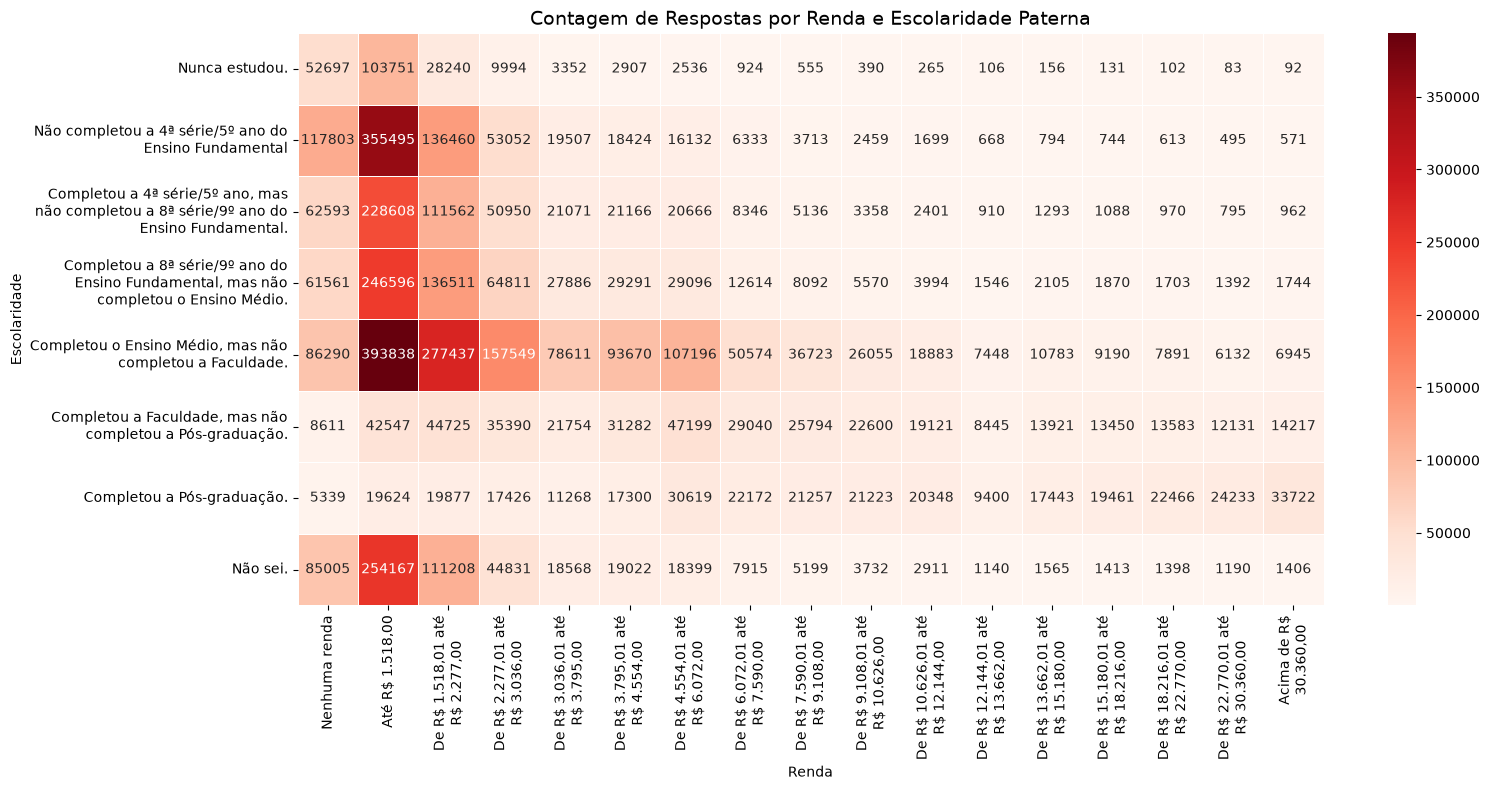

In [42]:
plt.figure(figsize=(16, 8))

ax = sns.heatmap(
    tabela_cruzada_renda_escol_pai.rename(index = q001eq002dic, columns=q007dic), 
    annot=True,          
    fmt='d',             
    cmap='Reds',      
    linewidths=0.5,      
    annot_kws={'size': 10}
)

# 3. Pega os textos atuais dos eixos e aplica a quebra baseada no limite de caracteres
labels_linhas = [item.get_text() for item in ax.get_yticklabels()]
labels_colunas = [item.get_text() for item in ax.get_xticklabels()]

# Ajuste o 'largura_max' conforme o seu gosto (ex: 30 caracteres por linha para as linhas, 15 para as colunas)
ax.set_yticklabels(quebrar_texto(labels_linhas, largura_max=35))
ax.set_xticklabels(quebrar_texto(labels_colunas, largura_max=20))

plt.title('Contagem de Respostas por Renda e Escolaridade Paterna', fontsize=14)
plt.xlabel('Renda', fontsize=10)
plt.ylabel('Escolaridade', fontsize=10)

plt.tight_layout()
plt.show()

In [43]:
tabela_com_totais_mae = tabela_com_totais_mae
tabela_com_totais_mae

Q007,A,B,C,D,E,F,G,H,I,J,K,L,M,N,O,P,Q,Total
Q002,,,,,,,,,,,,,,,,,,
A,34513,62100,18165,6872,2358,2072,1756,667,409,271,179,83,113,93,79,58,59,129847
B,94300,253007,89417,33776,11941,10748,9350,3712,2238,1399,993,386,494,457,388,316,283,513205
C,64457,205824,84617,35163,13570,12925,11610,4774,2820,1899,1384,532,740,646,562,481,470,442474
D,82927,300040,138739,57801,22969,22124,20472,8392,5144,3489,2560,1022,1346,1205,1031,825,940,671026
E,138290,599409,366543,183417,84941,92907,97856,43340,30095,21646,16100,6478,9229,8270,7433,6069,6338,1718361
F,15613,82218,80015,57673,32319,43521,57859,32116,26675,22652,18660,8079,13748,13305,13848,13211,16642,548154
G,11496,47926,50578,43970,27465,42102,66493,41940,37112,32533,28487,12587,21710,22748,24754,24943,34084,570928
H,38303,94102,37946,15331,6454,6663,6447,2977,1976,1498,1259,496,680,623,631,548,843,216777
Total,479899,1644626,866020,434003,202017,233062,271843,137918,106469,85387,69622,29663,48060,47347,48726,46451,59659,4810772


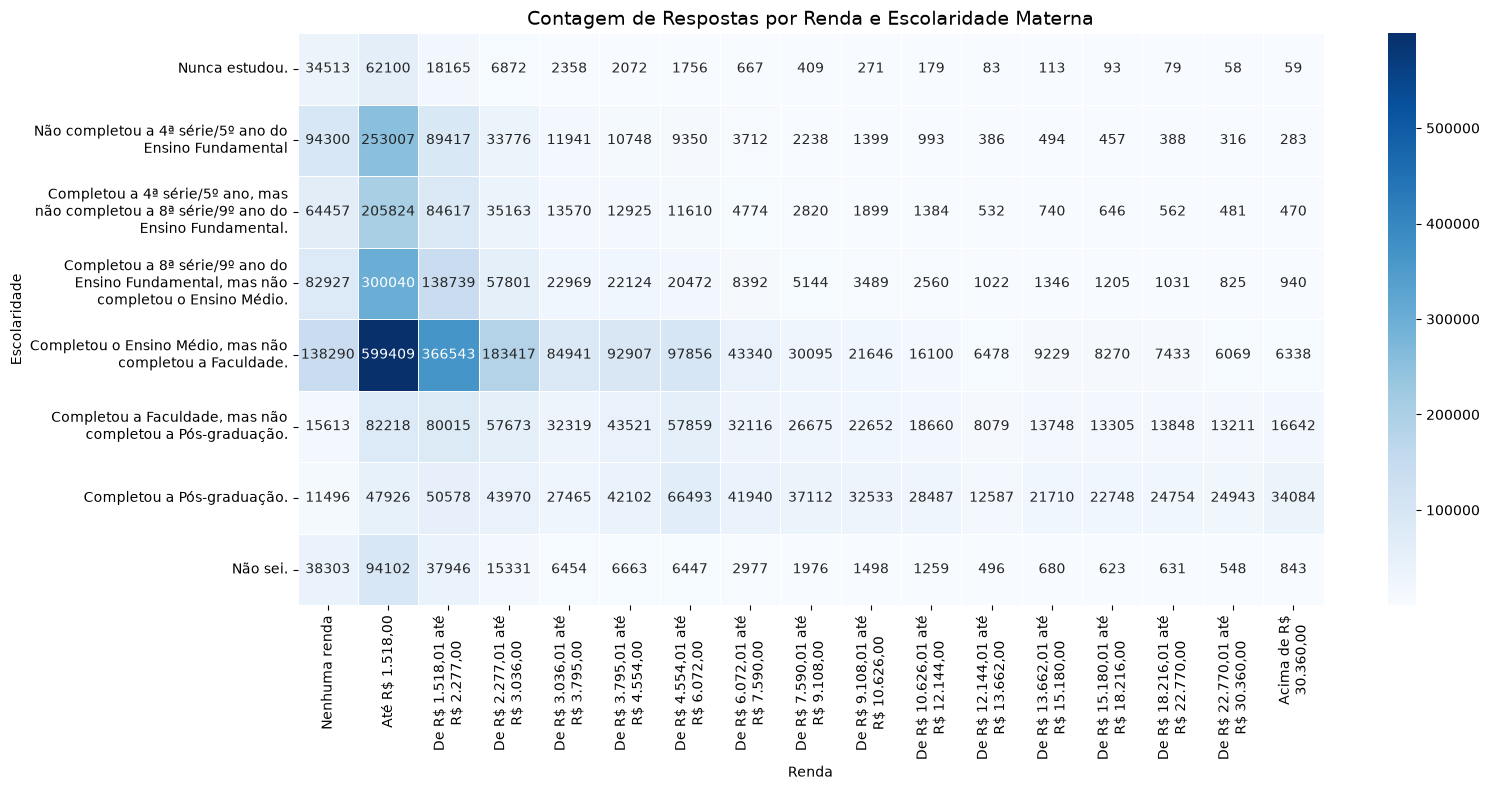

In [44]:
plt.figure(figsize=(16, 8))

ax = sns.heatmap(
    tabela_cruzada_renda_escol_mae.rename(index = q001eq002dic, columns=q007dic), 
    annot=True,          
    fmt='d',             
    cmap='Blues',      
    linewidths=0.5,      
    annot_kws={'size': 10}
)

# 3. Pega os textos atuais dos eixos e aplica a quebra baseada no limite de caracteres
labels_linhas = [item.get_text() for item in ax.get_yticklabels()]
labels_colunas = [item.get_text() for item in ax.get_xticklabels()]

# Ajuste o 'largura_max' conforme o seu gosto (ex: 30 caracteres por linha para as linhas, 15 para as colunas)
ax.set_yticklabels(quebrar_texto(labels_linhas, largura_max=35))
ax.set_xticklabels(quebrar_texto(labels_colunas, largura_max=20))

plt.title('Contagem de Respostas por Renda e Escolaridade Materna', fontsize=14)
plt.xlabel('Renda', fontsize=10)
plt.ylabel('Escolaridade', fontsize=10)

plt.tight_layout()
plt.show()

## Agora comparando em termos de raça

In [45]:
tabela_cruzada_renda_raca = pd.crosstab(
    EscolaridadePais['RACA'], 
    EscolaridadePais['Q007'], 
)

# 2. Adicionando os totais de cada linha e de cada coluna usando .margins=True
tabela_com_totais_raca = pd.crosstab(
    EscolaridadePais['RACA'], 
    EscolaridadePais['Q007'], 
    margins=True,          # Adiciona a linha e a coluna 'All' (Totais),
    margins_name='Total',  # Renomeia o rótulo de 'All' para 'Total'
)

In [46]:
tabela_cruzada_raca_escolaridade = pd.crosstab(
    EscolaridadePais['RACA'],
    EscolaridadePais['Q001'],
)

tabela_com_totais_raca_escol = pd.crosstab(
    EscolaridadePais['RACA'], 
    EscolaridadePais['Q001'], 
    margins=True,          # Adiciona a linha e a coluna 'All' (Totais),
    margins_name='Total',  # Renomeia o rótulo de 'All' para 'Total'
)

In [47]:
tabela_cruzada_raca_escolaridade_mae = pd.crosstab(
    EscolaridadePais['RACA'],
    EscolaridadePais['Q002'],
)

tabela_com_totais_raca_escol_mae = pd.crosstab(
    EscolaridadePais['RACA'], 
    EscolaridadePais['Q002'], 
    margins=True,          # Adiciona a linha e a coluna 'All' (Totais),
    margins_name='Total',  # Renomeia o rótulo de 'All' para 'Total'
)

In [48]:
# Somando as respostas dos candidatos com base em raça
df_resposta_raca = tabela_com_totais_raca[['Total']].iloc[:-1].reset_index()
df_resposta_raca

Q007,RACA,Total
0,Amarela,67199
1,Branca,1902820
2,Indígena,37480
3,Não decalrado,54305
4,Parda,2145936
5,Preta,603032


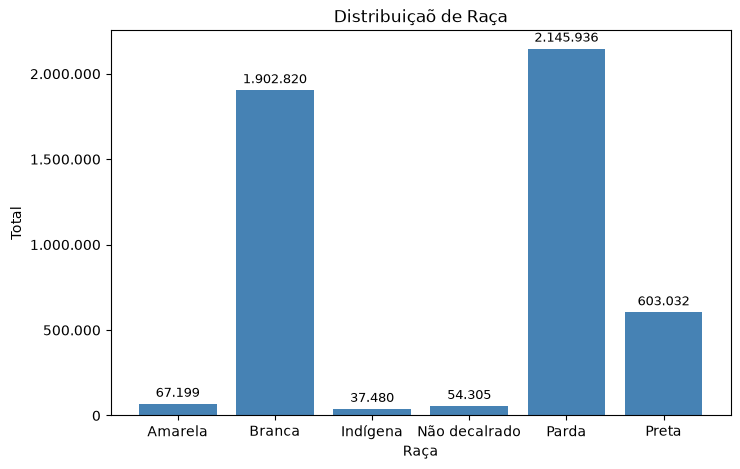

In [49]:
fig, ax = plt.subplots(figsize=(8, 5))
# Definindo colunas para o grafico de barras
histograma = ax.bar(df_resposta_raca["RACA"], df_resposta_raca["Total"], color="steelblue")
# Adicionando valores exatos acima das barras
ax.bar_label(
    histograma,
    labels=[f'{int(v):,}'.replace(',', '.') for v in df_resposta_raca["Total"]],
    padding=3,  # Espaço em pontos entre a barra e o texto
    fontsize=9  # Tamanho da fonte
)

# 1. Desativa a notação científica (tira o 10^6 do canto) e força o número plano
ax.ticklabel_format(style="plain", axis="y")

# 2. Formata o eixo Y com separadores de milhar (ex: 1.500.000)
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{int(x):,}".replace(",", "."))
)

# 3. Títulos e rótulos
# 3. Títulos e rótulos
plt.title("Distribuiçaõ de Raça")
ax.set_xlabel("Raça")
ax.set_ylabel("Total")

#Legenda



plt.show()

In [50]:
tabela_com_totais_raca = tabela_com_totais_raca.rename(columns = raca_dic)
tabela_com_totais_raca

Q007,A,B,C,D,E,F,G,H,I,J,K,L,M,N,O,P,Q,Total
RACA,,,,,,,,,,,,,,,,,,
Amarela,8177,23775,10902,5106,2330,2734,3466,1745,1452,1329,1037,452,844,857,873,941,1179,67199
Branca,105501,439733,320271,194191,100146,122796,155881,83992,67079,56422,46986,20383,33949,34283,36418,36100,48689,1902820
Indígena,8862,17564,5457,2089,819,815,690,342,225,152,114,61,68,64,59,42,57,37480
Não decalrado,7198,18388,9354,4576,2131,2544,2865,1465,1116,922,756,295,527,515,501,524,628,54305
Parda,272947,886206,397729,177847,76068,82971,88274,41212,30173,22156,17372,7105,10737,9966,9331,7693,8149,2145936
Preta,77214,258960,122307,50194,20523,21202,20667,9162,6424,4406,3357,1367,1935,1662,1544,1151,957,603032
Total,479899,1644626,866020,434003,202017,233062,271843,137918,106469,85387,69622,29663,48060,47347,48726,46451,59659,4810772


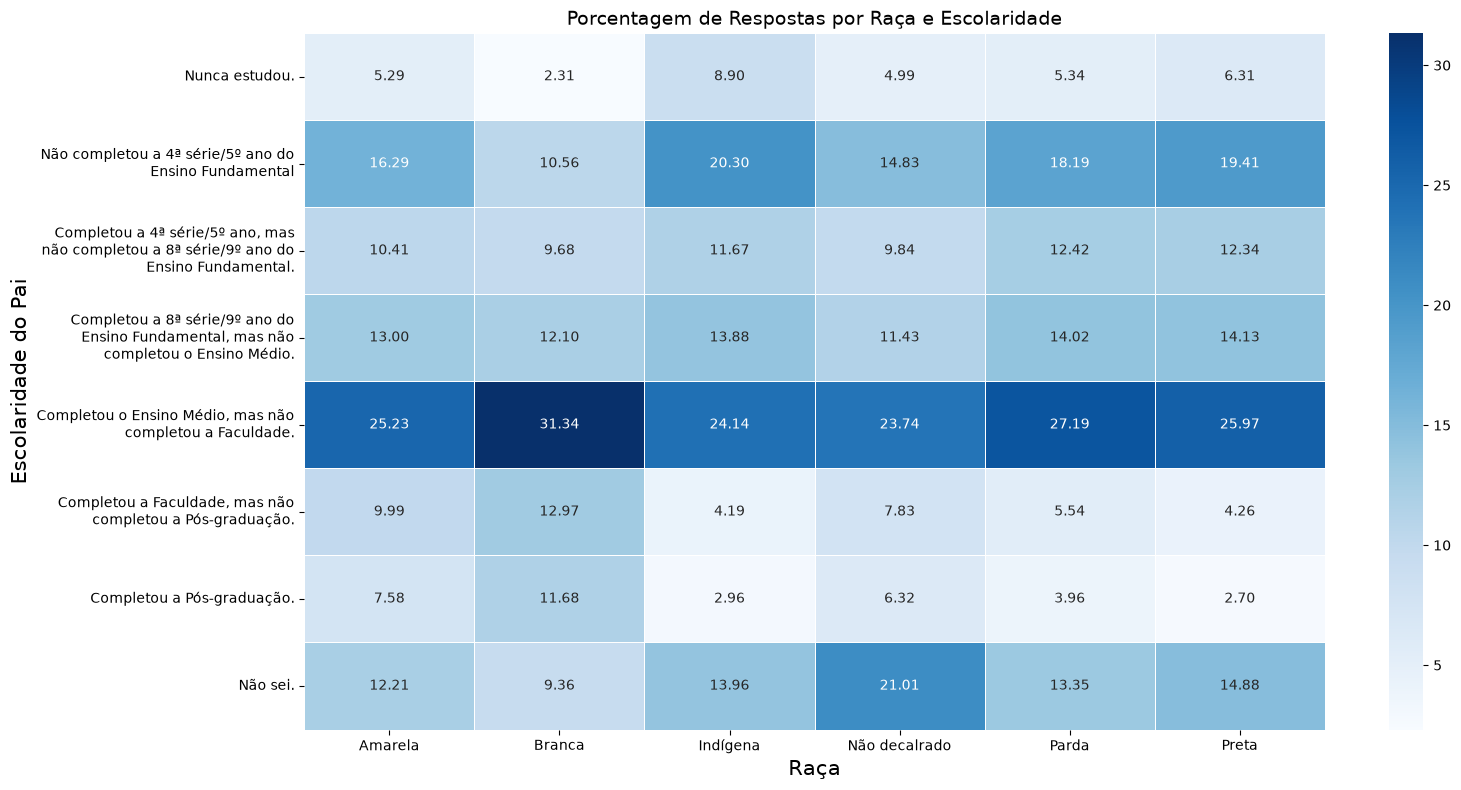

In [51]:
plt.figure(figsize=(16, 8))
#Como cada raça tem populações diferentes, vamos analisar as respostas com base em porcemtagens
tabela_porcentagem_coluna = (tabela_cruzada_raca_escolaridade.transpose() / tabela_cruzada_raca_escolaridade.transpose().sum()) * 100

ax = sns.heatmap(
    tabela_porcentagem_coluna.rename(index = q001eq002dic), 
    annot=True,          
    fmt='.2f',             
    cmap='Blues',      
    linewidths=0.5,      
    annot_kws={'size': 10}
)

# 3. Pega os textos atuais dos eixos e aplica a quebra baseada no limite de caracteres
labels_linhas = [item.get_text() for item in ax.get_yticklabels()]
labels_colunas = [item.get_text() for item in ax.get_xticklabels()]

# Ajuste o 'largura_max' conforme o seu gosto (ex: 30 caracteres por linha para as linhas, 15 para as colunas)
ax.set_yticklabels(quebrar_texto(labels_linhas, largura_max=35))
ax.set_xticklabels(quebrar_texto(labels_colunas, largura_max=20))

plt.title('Porcentagem de Respostas por Raça e Escolaridade', fontsize=14)
plt.xlabel('Raça', fontsize=15)
plt.ylabel('Escolaridade do Pai', fontsize=15)

plt.tight_layout()
plt.show()

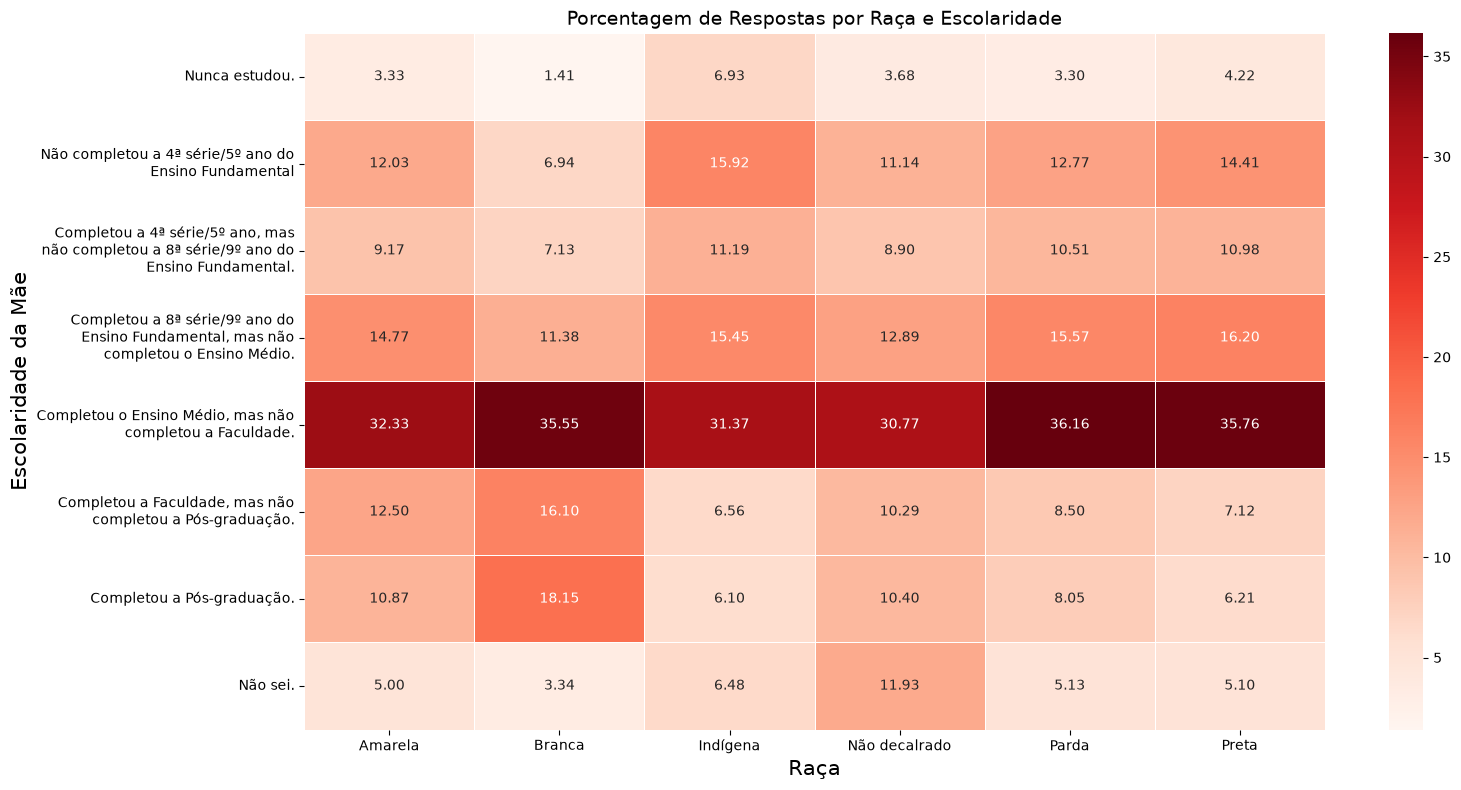

In [52]:
plt.figure(figsize=(16, 8))
#Como cada raça tem populações diferentes, vamos analisar as respostas com base em porcemtagens
tabela_porcentagem_coluna_mae = (tabela_cruzada_raca_escolaridade_mae.transpose() / tabela_cruzada_raca_escolaridade_mae.transpose().sum()) * 100

ax = sns.heatmap(
    tabela_porcentagem_coluna_mae.rename(index = q001eq002dic), 
    annot=True,          
    fmt='.2f',             
    cmap='Reds',      
    linewidths=0.5,      
    annot_kws={'size': 10}
)

# 3. Pega os textos atuais dos eixos e aplica a quebra baseada no limite de caracteres
labels_linhas = [item.get_text() for item in ax.get_yticklabels()]
labels_colunas = [item.get_text() for item in ax.get_xticklabels()]

# Ajuste o 'largura_max' conforme o seu gosto (ex: 30 caracteres por linha para as linhas, 15 para as colunas)
ax.set_yticklabels(quebrar_texto(labels_linhas, largura_max=35))
ax.set_xticklabels(quebrar_texto(labels_colunas, largura_max=20))

plt.title('Porcentagem de Respostas por Raça e Escolaridade', fontsize=14)
plt.xlabel('Raça', fontsize=15)
plt.ylabel('Escolaridade da Mãe', fontsize=15)

plt.tight_layout()
plt.show()